In [1]:
# Throw a ball at 100 different velocities.

import jax
import mediapy as media
import mujoco
from mujoco import mjx

XML = r"""
<mujoco>
  <worldbody>
    <body>
      <freejoint/>
      <geom size=".15" mass="1" type="sphere"/>
    </body>
  </worldbody>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(XML)
mjx_model = mjx.put_model(model)


@jax.vmap
def batched_step(vel):
    mjx_data = mjx.make_data(mjx_model)
    qvel = mjx_data.qvel.at[0].set(vel)
    mjx_data = mjx_data.replace(qvel=qvel)
    pos = mjx.step(mjx_model, mjx_data).qpos[0]
    return pos


vel = jax.numpy.arange(0.0, 1.0, 0.01)
pos = jax.jit(batched_step)(vel)

In [2]:
data = mjx.make_data(mjx_model)

print("number of position coordinates:", mjx_model.nq)
print("number of velocity coordinates:", mjx_model.nv)

print("joint positions:", data.qpos)
print("joint velocities:", data.qvel)
print("joint accelerations:", data.qacc)

print("body positions:", data.xpos)

number of position coordinates: 7
number of velocity coordinates: 6
joint positions: [0. 0. 0. 1. 0. 0. 0.]
joint velocities: [0. 0. 0. 0. 0. 0.]
joint accelerations: [0. 0. 0. 0. 0. 0.]
body positions: [[0. 0. 0.]
 [0. 0. 0.]]


""

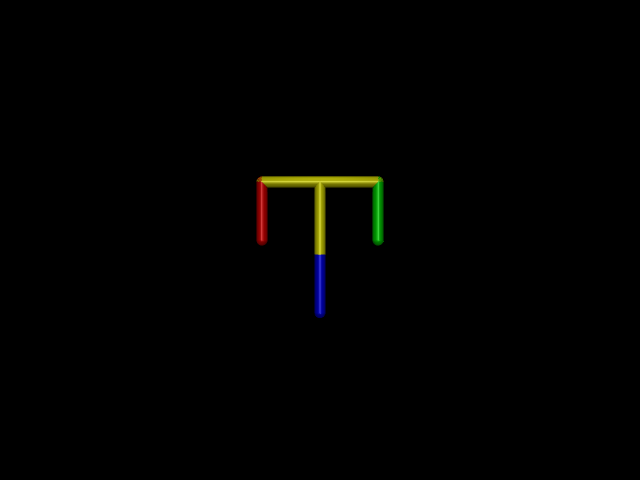

In [ ]:
chaotic_pendulum = r"""
<mujoco>
  <option timestep=".01" integrator="RK4"/>

  <default>
    <joint type="hinge" axis="0 -1 0"/>
    <geom type="capsule" size=".02"/>
  </default>

  <worldbody>
    <light pos="0 -.4 1"/>
    <camera name="fixed" pos="0 -2 0" xyaxes="1 0 0 0 0 1"/>
    <body name="0" pos="0 0 .2">
      <joint name="root"/>
      <geom fromto="-.2 0 0 .2 0 0" rgba="1 1 0 1"/>
      <geom fromto="0 0 0 0 0 -.25" rgba="1 1 0 1"/>
      <body name="1" pos="-.2 0 0">
        <joint/>
        <geom fromto="0 0 0 0 0 -.2" rgba="1 0 0 1"/>
      </body>
      <body name="2" pos=".2 0 0">
        <joint/>
        <geom fromto="0 0 0 0 0 -.2" rgba="0 1 0 1"/>
      </body>
      <body name="3" pos="0 0 -.25">
        <joint/>
        <geom fromto="0 0 0 0 0 -.2" rgba="0 0 1 1"/>
      </body>
    </body>
  </worldbody>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(chaotic_pendulum)
data = mujoco.MjData(model)
height = 480
width = 640

with mujoco.Renderer(model, height, width) as renderer:
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera="fixed")

    media.show_image(renderer.render())

In [4]:
model = mujoco.MjModel.from_xml_string(chaotic_pendulum)
mjx_model = mjx.put_model(model)
mjx_data = mjx.make_data(model)
mjx_data = mjx.step(mjx_model, mjx_data)

In [5]:
mjx_data._impl.contact

Contact(dist=Array([0.36      , 0.16615528, 0.16615528], dtype=float32), pos=Array([[ 0.        ,  0.        ,  0.09999875],
       [-0.10000001,  0.        , -0.025     ],
       [ 0.10000001,  0.        , -0.025     ]], dtype=float32), frame=Array([[[ 1.0000000e+00,  0.0000000e+00, -6.2398612e-06],
        [ 0.0000000e+00,  1.0000000e+00,  0.0000000e+00],
        [ 6.2398612e-06, -0.0000000e+00,  1.0000000e+00]],

       [[ 9.7014248e-01,  0.0000000e+00, -2.4253568e-01],
        [ 0.0000000e+00,  1.0000000e+00,  0.0000000e+00],
        [ 2.4253568e-01, -0.0000000e+00,  9.7014248e-01]],

       [[-9.7014248e-01,  0.0000000e+00, -2.4253568e-01],
        [ 0.0000000e+00,  1.0000000e+00,  0.0000000e+00],
        [ 2.4253568e-01,  0.0000000e+00, -9.7014248e-01]]], dtype=float32), includemargin=Array([0., 0., 0.], dtype=float32), friction=Array([[1.e+00, 1.e+00, 5.e-03, 1.e-04, 1.e-04],
       [1.e+00, 1.e+00, 5.e-03, 1.e-04, 1.e-04],
       [1.e+00, 1.e+00, 5.e-03, 1.e-04, 1.e-04]], dtype